# 💻 用 AReno 在 MacBook Air 上训练 Ling-3.0-tiny 支付助手

在本机 Mac 上打开 Notebook，选择 **Run** → **Run All Cells**。
<div class="align-center">

[](https://asystem-ai.io/docs/areno/getting-started/installation.html) [](https://asystem-ai.io/docs/areno/getting-started/installation.html) ⭐ [在 GitHub 上给 AReno 加星](https://github.com/inclusionAI/AReno) ⭐

</div>

在本机安装 AReno 的步骤见[安装指南](https://asystem-ai.io/docs/areno/getting-started/installation.html)。本 Notebook 采用 [Apache-2.0](https://www.apache.org/licenses/LICENSE-2.0) 许可证。

接下来我们会[准备模型与数据](#data)、[训练模型](#train)并[运行推理](#inference)。


<a id="setup"></a>

## 1. 🛠️ 安装


在 Apple Silicon Mac 上运行下面两条命令，从源码安装 AReno。运行本教程需要至少 **16GB 统一内存**和约 **25GB 可用磁盘空间**。


In [ ]:
%%bash
git clone https://github.com/inclusionAI/AReno.git AReno
pip install -e AReno

<a id="data"></a>

## 2. 📦 模型与数据


我们使用[原始 BF16 模型 Ling-3.0-tiny](https://huggingface.co/inclusionAI/Ling-3.0-tiny)，让模型读懂订单、账户余额和优惠规则，算出支付方案并给出更划算的推荐。

数据集包含 **1,115 条训练样本**（`train.jsonl`）、**100 条验证样本**（`valid.jsonl`）和 **500 道测试题**（`eval500.jsonl`）。[Ling-Ting-SFT-Augment](https://huggingface.co/datasets/AsystemAReno/Ling-Ting-SFT-Augment)

我们用一笔 **0.99 元** 的订单，看看两种支付方案。

**🧾 输入场景**

- 首选钱包余额 **0.21 元**，备选浦发卡余额 **2.97 元**。
- 通用优惠：满 **0.24 元**减 **0.02 元**；浦发卡优惠：满 **0.33 元**减 **0.19 元**，可叠加。

**输入节选**

```jsonc
{
  "order": {"order_amount": 99}, // 金额单位为分：99分=0.99元
  "selected_channel_id": "DIGITAL_RMB_WALLET_8752",
  "available_channels": [
    {"channel_id": "DIGITAL_RMB_WALLET_8752", "balance": 21},
    {"channel_id": "BANK_SPDB_CARD_2565", "balance": 297}
  ],
  "promotions": [
    // 通用减2分；使用浦发卡时还能叠加19分优惠
    {"applicable_channel_id": null, "threshold": 24, "discount_amount": 2},
    {"applicable_channel_id": "BANK_SPDB_CARD_2565", "threshold": 33, "discount_amount": 19}
  ]
}
```

**方案一：按首选钱包拆单**

- 优惠 **0.02 元**，应付 **0.97 元**。
- 钱包支付 **0.21 元**，浦发卡补足 **0.76 元**。

对应标准答案中的 `cashier_receipt`：

```jsonc
{
  "status": "SUCCESS",
  "cashier_receipt": {
    "primary_deduct_amount": 21,   // 首选钱包
    "secondary_deduct_amount": 76, // 浦发卡补足
    "total_discount_amount": 2,
    "payable_amount": 97
  }
}
```

**方案二：浦发卡单独支付（推荐）**

- 叠加优惠：**0.02 + 0.19 = 0.21 元**。
- 浦发卡支付 **0.78 元**，比拆单少付 **0.19 元**。

同一条标准答案中的 `recommended_option`：

```jsonc
{
  "recommended_option": {
    "recommended_channel_id": "BANK_SPDB_CARD_2565",
    "payable_amount": 78,         // 浦发卡单卡支付
    "total_discount_amount": 21
  }
}
```


<a id="train"></a>

## 3. 🚀 开始训练


接下来训练模型。我们用**在线 4bit 量化**加载基座，在全部 **24 层的 Attention 和 MLP 模块**上加 LoRA，训练 **500 步**。


In [ ]:
%%bash
train_args=(
  --algo sft --model-hub hf
  --ckpt inclusionAI/Ling-3.0-tiny
  --dataset-path AsystemAReno/Ling-Ting-SFT-Augment::train
  --dataset-loader-fn AReno/examples/sft/ling_payment/dataset_loader.py
  --validation-dataset-path AsystemAReno/Ling-Ting-SFT-Augment::validation
  # 在计划的更新前做验证，按受监督 token 数加权计算 loss。
  --eval-batches 25 --eval-before-step
  --shuffle --seed 0
  --q4  # 加载时将冻结的基座量化为 4bit。
  --lora-rank 4 --lora-alpha 32 --lora-dropout 0.05
  # 在全部 24 层的 Attention 和 MLP 中训练适配器，基座权重保持冻结。
  --lora-target-modules q_proj,k_proj,v_proj,f_proj,o_proj,g_proj,b_proj,q_a_proj,q_b_proj,kv_a_proj_with_mqa,dense,gate_proj,up_proj,down_proj
  # 每个微批次用一条样本，默认开启激活检查点。
  --batch-size 1 --mini-bs 1 --score-micro-bs 1
  --epochs 1 --max-steps 500
  --max-new-tokens 1024
  --lr 2e-5 --min-lr 2e-5 --lr-decay-style constant --weight-decay 0
  --no-adam-bias-correction  # 跳过 Adam 对零初始化矩估计的偏差修正。
  --no-grad-clip  
  --no-mlx-compile-train-step  # 不用 mx.compile 编译损失与梯度计算函数。
  --save-path runs/q4-cli/adapters  # 默认每 100 步保存一次适配器。
  --metrics-log-dir runs/q4-cli/events
)
areno train "${train_args[@]}"


我们用 `--save-path` 将 LoRA 适配器保存到本地。最后一步的适配器位于 `runs/q4-cli/adapters/step_000500/`。

接下来启动 Dashboard 查看训练指标。


In [ ]:
%%bash
areno dashboard --start


打开 [AReno Dashboard](http://127.0.0.1:8765)，在 **Jobs** 中查看 loss、每步耗时和日志。

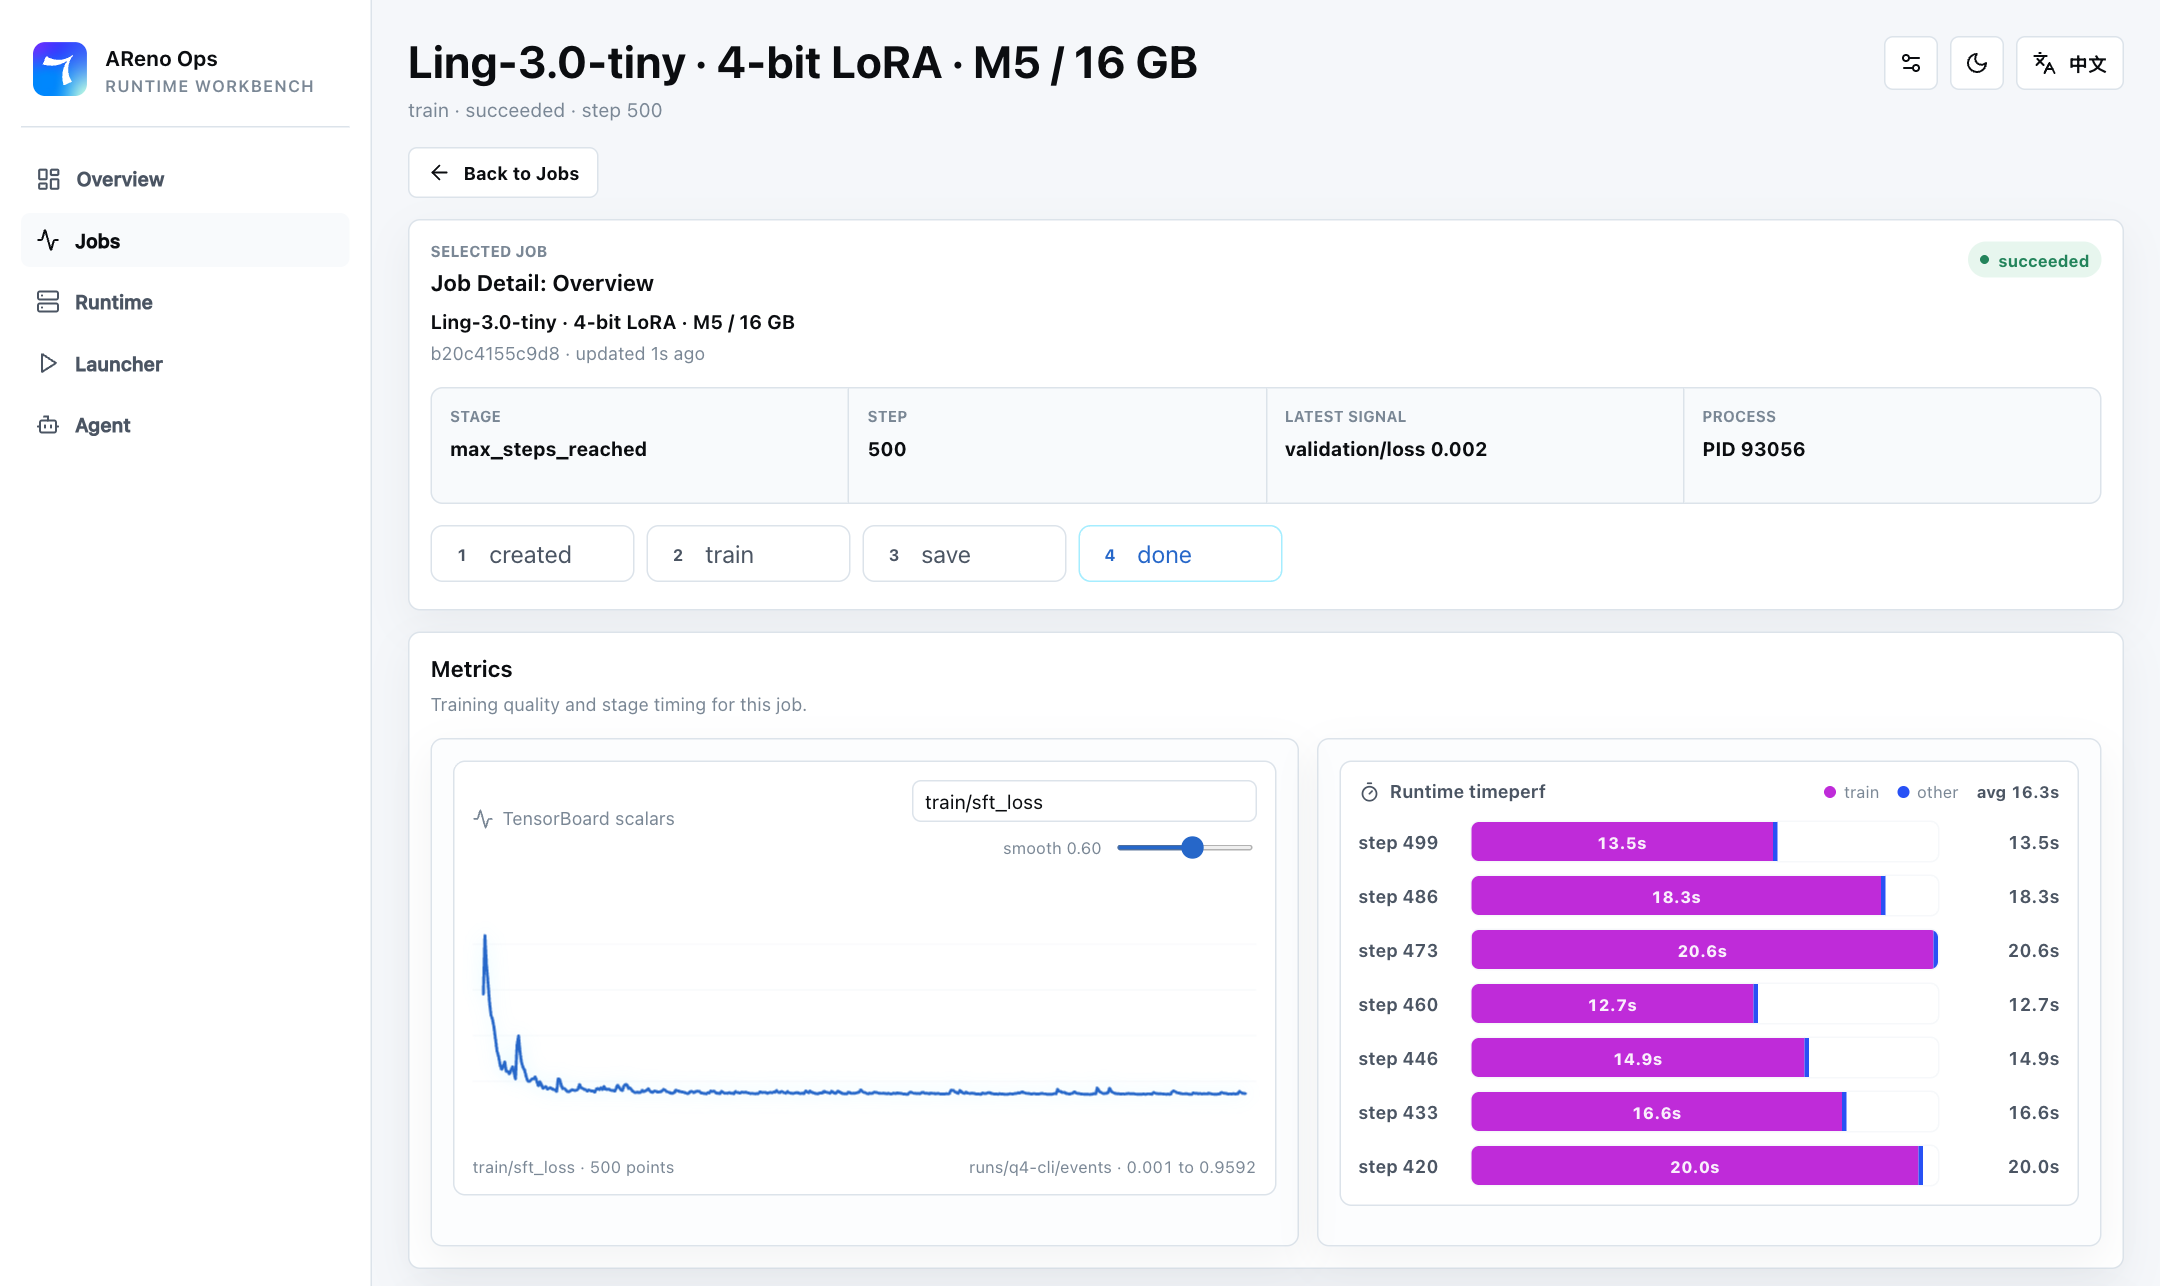

*图 1：本次 500 步训练在 Dashboard 中的记录。*

更多功能：[DPO / GRPO / GSPO / PPO](https://asystem-ai.io/docs/areno/cli/training.html) · [Agentic RL](https://asystem-ai.io/docs/areno/getting-started/welcome.html#agentic-rollout) · [8-bit AdamW](https://asystem-ai.io/docs/areno/concepts/adamw-8bit.html)。


<a id="inference"></a>

## 4. 🧪 推理


来运行模型吧！用 `areno serve` 加载刚才保存的 LoRA 适配器，启动 **OpenAI 兼容服务**。


In [ ]:
%%bash --bg
areno serve \
  --backend mlx \
  --model-hub hf \
  --model-path inclusionAI/Ling-3.0-tiny \
  --lora-adapter-path runs/q4-cli/adapters/step_000500 \
  --host 127.0.0.1 --port 8000 \
  --max-running-prompts 2 --default-max-tokens 4096

服务就绪后，我们评测 **500 道支付题**。脚本只发送规则和问题，并将回答保存到 `eval_results.jsonl`。

评分时，将模型最终输出的 JSON 与标准答案逐项比较。字段值和数组顺序必须一致，JSON 对象的键顺序不限。无法解析为 JSON 的回答记错。


In [ ]:
import json
from pathlib import Path
from huggingface_hub import hf_hub_download
from openai import OpenAI

client = OpenAI(base_url="http://127.0.0.1:8000/v1", api_key="local", timeout=600)
model = client.models.list().data[0].id
eval_path = Path(hf_hub_download(
    repo_id="AsystemAReno/Ling-Ting-SFT-Augment",
    filename="eval500.jsonl",
    repo_type="dataset",
))
cases = [json.loads(line) for line in eval_path.read_text(encoding="utf-8").splitlines() if line.strip()]
results = []

for i, case in enumerate(cases, 1):
    response = client.chat.completions.create(
        model=model,
        # 只发送规则和问题，不发送样本中的 assistant 答案
        messages=[m for m in case["messages"] if m["role"] != "assistant"],
        temperature=0.1,
        max_tokens=4096,
    )
    answer = response.choices[0].message.content or ""
    try:
        prediction = json.loads(answer.rsplit("</think>", 1)[-1].strip())
        correct = prediction == case["ground_truth"]
    except json.JSONDecodeError:
        correct = False
    results.append({"case_id": case["case_id"], "correct": correct, "output": answer})
    print(f"已完成 {i}/{len(cases)}", end="\r")

Path("eval_results.jsonl").write_text(
    "\n".join(json.dumps(row, ensure_ascii=False) for row in results) + "\n",
    encoding="utf-8",
)
correct = sum(row["correct"] for row in results)
print(f"\n测试集正确率： {correct}/{len(cases)} = {correct / len(cases):.2%}")

<a id="results"></a>

我们在 **MacBook Air（M5，16GB 统一内存）**上训练了 **500 步**。LoRA 参数量为 **74,947,584**，训练耗时 **3 小时 15 分 55 秒**，MLX 分配器记录的峰值约为 **10.03GB**。

我们的支付小助手答对了 **322/500** 题，完整答案正确率为 **64.4%**。相比已有 **0%** 基线提升了 **64.4 个百分点**。

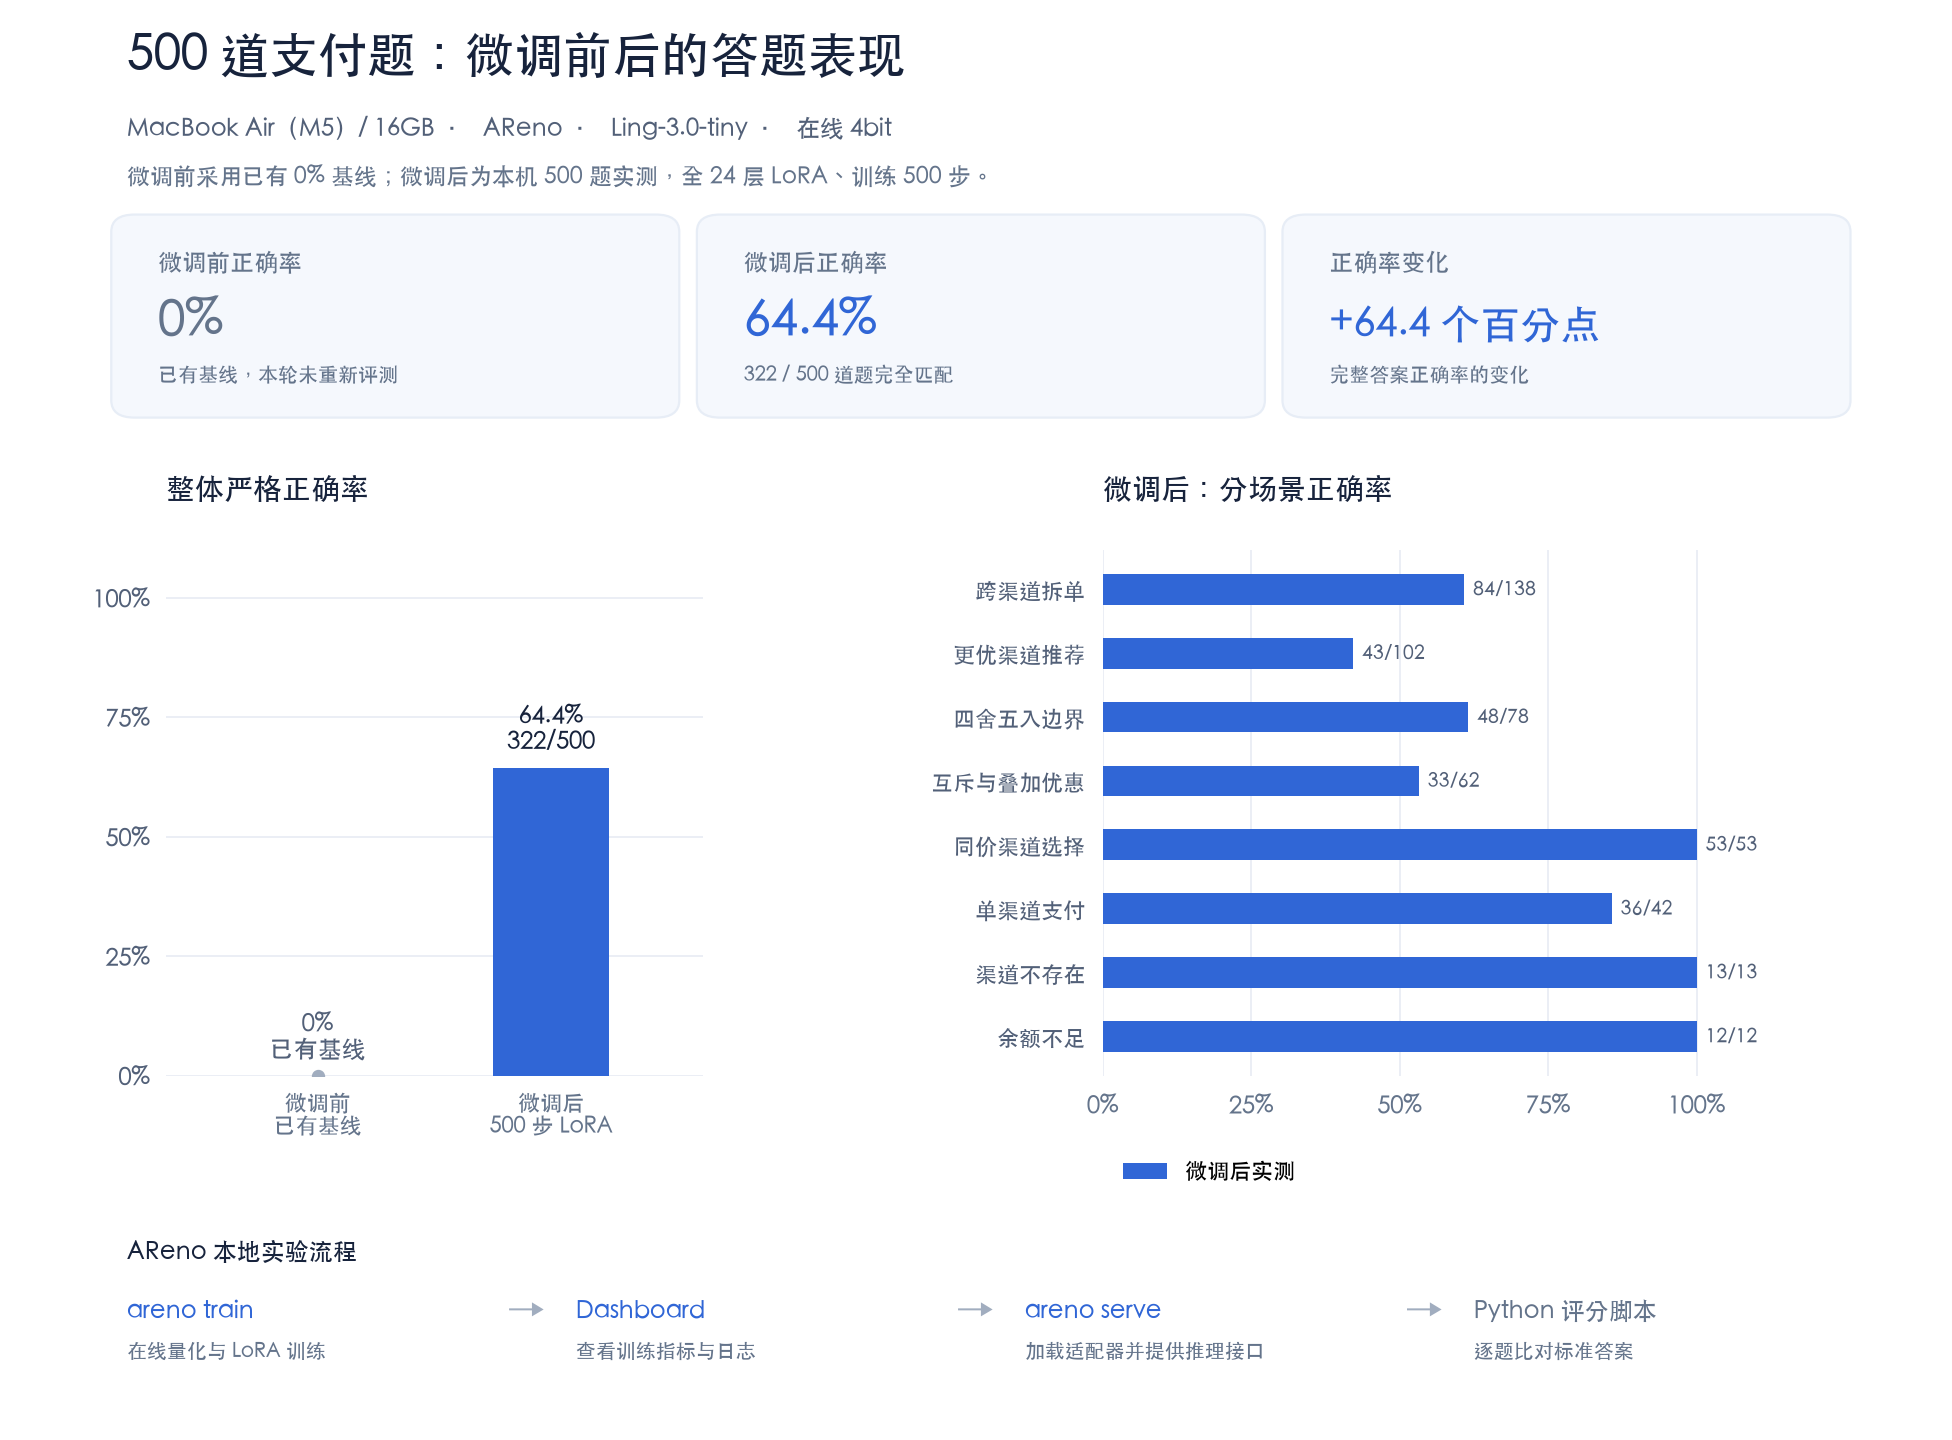

*图 2：左侧对比整体正确率，右侧展示微调后的分场景实测，数字为正确题数 / 该场景题数。场景沿用测试集的原始标签。微调前采用已有基线，本轮未重新评测。*
